# GARCH y VaR condicional: diagnosticar el modelo antes de confiar en su pronóstico

**Perfil:** Riesgo financiero y riesgo de modelos  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

Un modelo GARCH ajusta "bien" casi cualquier serie financiera. ¿Cómo se sabe que **este** GARCH es el correcto? ¿Qué diagnósticos delatan un modelo simétrico cuando la verdad tiene **efecto apalancamiento** y colas pesadas, y cuánto cambia el VaR?

## Recorrido

1. Mundo verdadero: **GJR-GARCH(1,1) con innovaciones t** (la volatilidad reacciona más a las caídas).
2. **Versión 0:** volatilidad constante. **Versión 1:** GARCH(1,1) normal. **Versión 2:** GJR-GARCH(1,1) con t.
3. **Diagnósticos:** efectos ARCH, autocorrelación de residuos al cuadrado, sesgo de signo, QQ de residuos.
4. **Recuperación de parámetros** por tamaño de muestra (Monte Carlo) y curva de impacto de noticias.
5. **VaR fuera de muestra:** cobertura, independencia y pérdida de cuantil.
6. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy import stats
from arch import arch_model
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
import statsmodels.api as sm

## 2. El mundo verdadero

Retornos en **porcentaje**. Con $h_t$ la varianza condicional,
$$r_t=\sqrt{h_t}\,z_t,\qquad h_t=\omega+\big(\alpha+\gamma\,\mathbf 1\{r_{t-1}<0\}\big)r_{t-1}^2+\beta\,h_{t-1},\qquad z_t\sim t_\nu\ (\text{estandarizada}).$$
Parámetros: $\omega=0{,}02$, $\alpha=0{,}04$, $\gamma=0{,}08$, $\beta=0{,}90$, $\nu=6$. La **persistencia** es $\alpha+\beta+\gamma/2=0{,}98$ y la varianza incondicional $\omega/(1-0{,}98)=1\%^2$.

persistencia = 0.980 | varianza incondicional = 1.000 (%^2)
desvio muestral = 0.998 | curtosis exceso = 5.5 | asimetria = -0.05


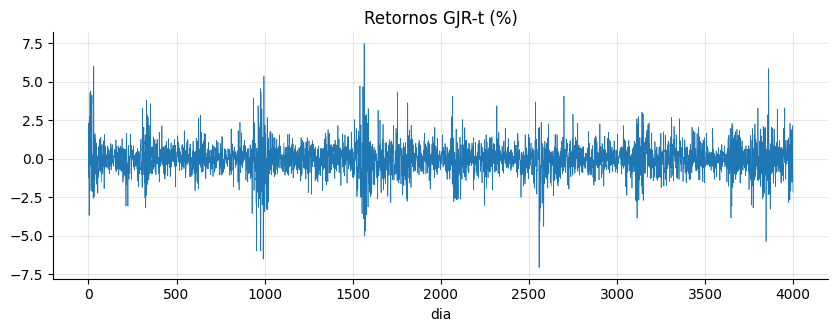

In [2]:
OM, AL, GA, BE, NU = 0.02, 0.04, 0.08, 0.90, 6.0
PERS = AL + BE + GA / 2
print(f"persistencia = {PERS:.3f} | varianza incondicional = {OM / (1 - PERS):.3f} (%^2)")

def simular_gjr(T, seed, burn=1000):
    rg = np.random.default_rng(seed); n = T + burn
    z = rg.standard_t(NU, n) * np.sqrt((NU - 2) / NU)
    r = np.zeros(n); h = np.zeros(n); h[0] = OM / (1 - PERS)
    for t in range(1, n):
        h[t] = OM + (AL + GA * (r[t - 1] < 0)) * r[t - 1] ** 2 + BE * h[t - 1]
        r[t] = np.sqrt(h[t]) * z[t]
    return r[burn:], h[burn:]

r, h_ver = simular_gjr(4000, 2026)
print(f"desvio muestral = {r.std():.3f} | curtosis exceso = {stats.kurtosis(r):.1f} | asimetria = {stats.skew(r):.2f}")
fig, ax = plt.subplots(figsize=(10, 3.2)); ax.plot(r, lw=0.5); ax.set_title("Retornos GJR-t (%)"); ax.set_xlabel("dia"); plt.show()

## 3. Versión 0: ¿hay algo que modelar? Efectos ARCH

Si la volatilidad fuera constante, $r_t^2$ no tendría autocorrelación. Se contrasta con **Ljung-Box** sobre $r_t^2$ y con la **prueba ARCH-LM** de Engle.

In [3]:
lb = acorr_ljungbox(r ** 2, lags=[10, 20], return_df=True)
lm, p_lm, _, _ = het_arch(r, nlags=10)
ac_r = [np.corrcoef(r[k:], r[:-k])[0, 1] for k in (1, 2, 3)]
ac_r2 = [np.corrcoef(r[k:] ** 2, r[:-k] ** 2)[0, 1] for k in (1, 2, 3, 10)]
print(f"Autocorrelacion de r (rezagos 1-3):   {np.round(ac_r, 3)}  (sin estructura en el nivel)")
print(f"Autocorrelacion de r^2 (1,2,3,10):     {np.round(ac_r2, 3)}  (fuerte: agrupamiento de volatilidad)")
print(f"Ljung-Box sobre r^2: p(10)={lb['lb_pvalue'].iloc[0]:.2e}, p(20)={lb['lb_pvalue'].iloc[1]:.2e} | ARCH-LM(10): p={p_lm:.2e}")

Autocorrelacion de r (rezagos 1-3):   [-0.059  0.056 -0.052]  (sin estructura en el nivel)
Autocorrelacion de r^2 (1,2,3,10):     [0.204 0.191 0.187 0.156]  (fuerte: agrupamiento de volatilidad)
Ljung-Box sobre r^2: p(10)=1.29e-261, p(20)=0.00e+00 | ARCH-LM(10): p=3.39e-98


**Qué muestra.** Los retornos casi no tienen autocorrelación, pero sus **cuadrados** sí, y mucha: hay estructura en la **volatilidad**. Un VaR con desvío constante ignora esa estructura.

## 4. Versiones 1 y 2: ajustar GARCH normal y GJR-t

Se ajustan los dos modelos por máxima verosimilitud sobre toda la serie y se comparan por verosimilitud, AIC y BIC. Los parámetros verdaderos se conocen y se comparan.

In [4]:
def ajustar(r, vol="GARCH", o=0, dist="normal"):
    am = arch_model(r, mean="Zero", vol=vol, p=1, o=o, q=1, dist=dist)
    return am.fit(disp="off", options={"maxiter": 500})

res_g = ajustar(r, o=0, dist="normal")
res_j = ajustar(r, o=1, dist="t")
tabla = pd.DataFrame({
    "verdadero": {"omega": OM, "alpha[1]": AL, "gamma[1]": GA, "beta[1]": BE, "nu": NU, "persistencia": PERS},
    "GARCH(1,1) normal": {**res_g.params.to_dict(), "persistencia": res_g.params["alpha[1]"] + res_g.params["beta[1]"]},
    "GJR(1,1) t": {**res_j.params.to_dict(), "persistencia": res_j.params["alpha[1]"] + res_j.params["beta[1]"] + res_j.params["gamma[1]"] / 2},
})
print(tabla.round(4).to_string())
comp = pd.DataFrame({"loglik": [res_g.loglikelihood, res_j.loglikelihood], "AIC": [res_g.aic, res_j.aic], "BIC": [res_g.bic, res_j.bic], "parametros": [len(res_g.params), len(res_j.params)]},
                    index=["GARCH(1,1) normal", "GJR(1,1) t"])
comp.round(1)

              verdadero  GARCH(1,1) normal  GJR(1,1) t
omega            0.0200             0.0189      0.0182
alpha[1]         0.0400             0.0809      0.0318
gamma[1]         0.0800                NaN      0.0769
beta[1]          0.9000             0.8990      0.9093
nu               6.0000                NaN      5.9642
persistencia     0.9800             0.9798      0.9796


,loglik,AIC,BIC,parametros
"GARCH(1,1) normal","-5,144.5000","10,294.9000","10,313.8000",3
"GJR(1,1) t","-5,011.6000","10,033.2000","10,064.7000",5


In [5]:
print("Lectura:")
print(f"  El GJR-t gana por AIC en {comp.loc['GARCH(1,1) normal', 'AIC'] - comp.loc['GJR(1,1) t', 'AIC']:,.0f} puntos y por BIC en {comp.loc['GARCH(1,1) normal', 'BIC'] - comp.loc['GJR(1,1) t', 'BIC']:,.0f}.")
print(f"  El GARCH normal estima alpha+beta = {tabla.loc['persistencia', 'GARCH(1,1) normal']:.3f} frente a una persistencia verdadera de {PERS:.3f}.")

Lectura:
  El GJR-t gana por AIC en 262 puntos y por BIC en 249.
  El GARCH normal estima alpha+beta = 0.980 frente a una persistencia verdadera de 0.980.


## 5. Diagnóstico: ¿qué delata al modelo equivocado?

Si el modelo es correcto, los **residuos estandarizados** $\hat z_t=r_t/\hat\sigma_t$ deben comportarse como una muestra i.i.d. de la innovación supuesta. Se miran cuatro cosas:

1. **Ljung-Box sobre $\hat z_t^2$:** ¿queda agrupamiento de volatilidad sin explicar?
2. **ARCH-LM sobre $\hat z_t$.**
3. **Sesgo de signo (Engle-Ng):** regresión de $\hat z_t^2$ sobre $\mathbf 1\{\hat z_{t-1}<0\}$. Un coeficiente significativo indica que la **dirección** del retorno pasado importa y el modelo no la recoge (efecto apalancamiento).
4. **QQ:** ¿la distribución supuesta describe las colas?

In [6]:
def diagnosticos(res):
    z = np.asarray(res.std_resid); z = z[~np.isnan(z)]
    lb = acorr_ljungbox(z ** 2, lags=[10], return_df=True)["lb_pvalue"].iloc[0]
    _, p_arch, _, _ = het_arch(z, nlags=10)
    neg = (z[:-1] < 0).astype(float); ols = sm.OLS(z[1:] ** 2, sm.add_constant(neg)).fit()
    return {"LjungBox(z2) p": lb, "ARCH-LM p": p_arch, "sesgo de signo: t": ols.tvalues[1], "sesgo de signo: p": ols.pvalues[1]}

diag = pd.DataFrame({"GARCH(1,1) normal": diagnosticos(res_g), "GJR(1,1) t": diagnosticos(res_j)}).T
diag.round(4)

,LjungBox(z2) p,ARCH-LM p,sesgo de signo: t,sesgo de signo: p
"GARCH(1,1) normal",0.4787,0.4863,1.1405,0.2542
"GJR(1,1) t",0.4319,0.4306,0.1814,0.8561


In [7]:
print("Lectura (nivel 5%):")
for m in diag.index:
    d = diag.loc[m]
    fallos = [n for n, c in (("agrupamiento residual", d["LjungBox(z2) p"] < 0.05), ("efectos ARCH residuales", d["ARCH-LM p"] < 0.05), ("sesgo de signo", d["sesgo de signo: p"] < 0.05)) if c]
    print(f"  {m:18s}: " + ("pasa los tres diagnosticos" if not fallos else "FALLA: " + ", ".join(fallos)))
if not [n for n in range(1) if diag.loc["GARCH(1,1) normal", ["LjungBox(z2) p", "ARCH-LM p", "sesgo de signo: p"]].lt(0.05).any()]:
    print("  OJO: el GARCH normal esta MAL especificado (la verdad es asimetrica y de colas pesadas) y AUN ASI pasa los tres diagnosticos clasicos en esta muestra.")

Lectura (nivel 5%):
  GARCH(1,1) normal : pasa los tres diagnosticos
  GJR(1,1) t        : pasa los tres diagnosticos
  OJO: el GARCH normal esta MAL especificado (la verdad es asimetrica y de colas pesadas) y AUN ASI pasa los tres diagnosticos clasicos en esta muestra.


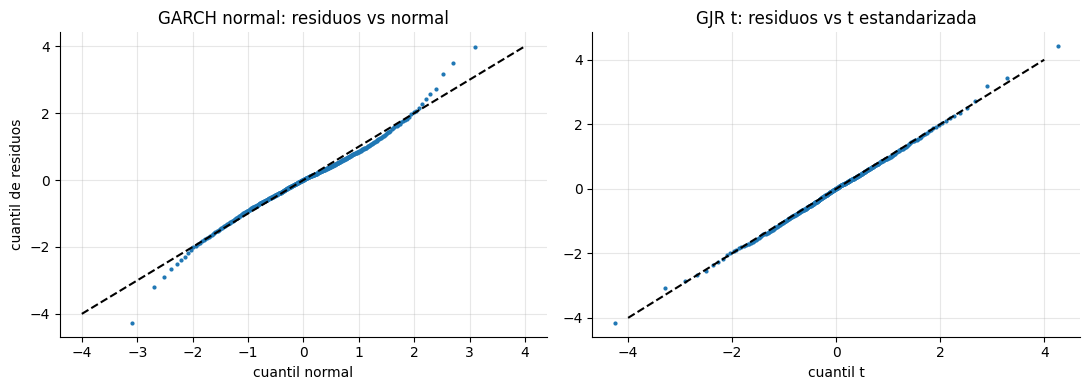

Fraccion de residuos del GARCH normal por debajo de -2.326 (esperado 1% si fueran normales): 1.47%
Fraccion de residuos del GJR-t por debajo de su cuantil 1% t estandarizado: 1.07%


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
z_g = np.asarray(res_g.std_resid); z_j = np.asarray(res_j.std_resid)
# QQ de los residuos contra la distribucion SUPUESTA por cada modelo
q = np.linspace(0.001, 0.999, 400)
ax[0].plot(stats.norm.ppf(q), np.quantile(z_g, q), "o", ms=2); ax[0].plot([-4, 4], [-4, 4], "k--"); ax[0].set_title("GARCH normal: residuos vs normal"); ax[0].set_xlabel("cuantil normal"); ax[0].set_ylabel("cuantil de residuos")
nu_h = res_j.params["nu"]; esc = np.sqrt((nu_h - 2) / nu_h)
ax[1].plot(stats.t.ppf(q, nu_h) * esc, np.quantile(z_j, q), "o", ms=2); ax[1].plot([-4, 4], [-4, 4], "k--"); ax[1].set_title("GJR t: residuos vs t estandarizada"); ax[1].set_xlabel("cuantil t")
plt.tight_layout(); plt.show()
cola_g = np.mean(z_g < -stats.norm.ppf(0.99) * 1) ;
print(f"Fraccion de residuos del GARCH normal por debajo de -2.326 (esperado 1% si fueran normales): {np.mean(z_g < -2.326):.2%}")
print(f"Fraccion de residuos del GJR-t por debajo de su cuantil 1% t estandarizado: {np.mean(z_j < stats.t.ppf(0.01, nu_h) * esc):.2%}")

### 5.1 ¿Qué diagnósticos tienen potencia? Un experimento sobre 100 series

Que el GARCH simétrico pase los diagnósticos clásicos en una muestra es solo **una** observación. Se repite sobre 100 series independientes de 4.000 días y se mide, para cada herramienta, la **frecuencia con que delata** al modelo simétrico:

- los tres diagnósticos sobre residuos (nivel 5 %);
- una **prueba de razón de verosimilitudes de asimetría**: GJR frente a GARCH, ambos con innovaciones normales (modelos anidados, $\chi^2_1$);
- una prueba binomial sobre la **cola** de los residuos (¿su fracción bajo −2,326 es 1 %?);
- el **AIC** (¿prefiere al GJR-t?).

In [9]:
def una_replica(seed, T=4000):
    r_, _ = simular_gjr(T, seed)
    g = ajustar(r_, o=0, dist="normal"); gj_n = ajustar(r_, o=1, dist="normal"); gj_t = ajustar(r_, o=1, dist="t")
    d = diagnosticos(g); z = np.asarray(g.std_resid)
    lr_asim = 2 * (gj_n.loglikelihood - g.loglikelihood)
    return {"LB(z2)": d["LjungBox(z2) p"] < 0.05, "ARCH-LM": d["ARCH-LM p"] < 0.05, "sesgo de signo": d["sesgo de signo: p"] < 0.05,
            "LR de asimetria (GJR vs GARCH)": (1 - stats.chi2.cdf(lr_asim, 1)) < 0.05,
            "cola de residuos (binomial)": stats.binomtest(int((z < -2.326).sum()), len(z), 0.01).pvalue < 0.05,
            "AIC prefiere GJR-t": gj_t.aic < g.aic}

pot = pd.DataFrame([una_replica(2000 + i) for i in range(100)])
potencia = pot.mean().rename("frecuencia con que delata al GARCH simetrico").to_frame()
potencia.round(2)

,frecuencia con que delata al GARCH simetrico
LB(z2),0.0100
ARCH-LM,0.0000
sesgo de signo,0.1600
LR de asimetria (GJR vs GARCH),0.9800
cola de residuos (binomial),0.8900
AIC prefiere GJR-t,1.0000


In [10]:
print("Lectura (100 series de 4000 dias; el GARCH normal esta mal especificado en todas):")
for k, v in potencia.iloc[:, 0].items():
    print(f"  {k:34s}: lo delata en {v:.0%} de las series")
clasicos = potencia.loc[["LB(z2)", "ARCH-LM", "sesgo de signo"]].iloc[:, 0].max()
print(f"  Los tres diagnosticos clasicos sobre residuos delatan al modelo mal especificado como maximo en el {clasicos:.0%} de las series (con un modelo CORRECTO se esperaria 5% por azar): practicamente no distinguen un modelo bueno de uno malo aqui.")
print(f"  El contraste de razon de verosimilitudes de asimetria lo delata en {potencia.loc['LR de asimetria (GJR vs GARCH)'].iloc[0]:.0%}, y el AIC elige al GJR-t en {potencia.loc['AIC prefiere GJR-t'].iloc[0]:.0%}.")

Lectura (100 series de 4000 dias; el GARCH normal esta mal especificado en todas):
  LB(z2)                            : lo delata en 1% de las series
  ARCH-LM                           : lo delata en 0% de las series
  sesgo de signo                    : lo delata en 16% de las series
  LR de asimetria (GJR vs GARCH)    : lo delata en 98% de las series
  cola de residuos (binomial)       : lo delata en 89% de las series
  AIC prefiere GJR-t                : lo delata en 100% de las series
  Los tres diagnosticos clasicos sobre residuos delatan al modelo mal especificado como maximo en el 16% de las series (con un modelo CORRECTO se esperaria 5% por azar): practicamente no distinguen un modelo bueno de uno malo aqui.
  El contraste de razon de verosimilitudes de asimetria lo delata en 98%, y el AIC elige al GJR-t en 100%.


**Qué se aprende.** Los diagnósticos sobre residuos **estandarizados** casi no tienen potencia contra esta mala especificación: el GARCH simétrico absorbe la asimetría **promediándola** en un $\hat\alpha$ más grande (≈ el doble del verdadero), y lo que queda en los residuos no se ve con esas pruebas. Hay que comparar **modelos** (verosimilitud, AIC, razón de verosimilitudes anidada), no solo mirar los residuos de uno.

## 6. La curva de impacto de noticias

La **curva de impacto de noticias** muestra cuánto sube la varianza de mañana según el retorno de hoy $r_{t-1}$, manteniendo $h_{t-1}$ en su valor incondicional. Un GARCH simétrico es una parábola; el GJR es asimétrico. Se compara la verdadera con las dos estimadas.

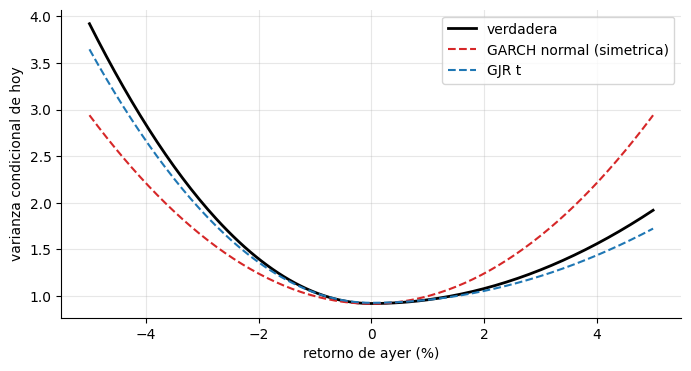

Cociente de la reaccion a un retorno de -5% frente a +5%: verdadero 3.00 | GARCH normal 1.00 | GJR t 3.42


In [11]:
rr = np.linspace(-5, 5, 201); h_bar = OM / (1 - PERS)
nic_ver = OM + (AL + GA * (rr < 0)) * rr ** 2 + BE * h_bar
pg = res_g.params; pj = res_j.params
nic_g = pg["omega"] + pg["alpha[1]"] * rr ** 2 + pg["beta[1]"] * h_bar
nic_j = pj["omega"] + (pj["alpha[1]"] + pj["gamma[1]"] * (rr < 0)) * rr ** 2 + pj["beta[1]"] * h_bar
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(rr, nic_ver, "k", lw=2, label="verdadera"); ax.plot(rr, nic_g, "C3--", label="GARCH normal (simetrica)"); ax.plot(rr, nic_j, "C0--", label="GJR t")
ax.set_xlabel("retorno de ayer (%)"); ax.set_ylabel("varianza condicional de hoy"); ax.legend(); plt.show()
asim_ver = nic_ver[rr == rr[0]][0] / nic_ver[-1] if False else (nic_ver[0] - nic_ver[100]) / (nic_ver[-1] - nic_ver[100])
print(f"Cociente de la reaccion a un retorno de -5% frente a +5%: verdadero {(nic_ver[0] - nic_ver[100]) / (nic_ver[-1] - nic_ver[100]):.2f} | GARCH normal {(nic_g[0] - nic_g[100]) / (nic_g[-1] - nic_g[100]):.2f} | GJR t {(nic_j[0] - nic_j[100]) / (nic_j[-1] - nic_j[100]):.2f}")

## 7. Recuperación de parámetros: ¿cuántos datos hacen falta?

Se simulan muchas series de longitud $T$ y se ajusta el GJR-t. Se mide el **sesgo** y el **error** de cada parámetro y de la persistencia. Los parámetros de GARCH son conocidos por ser difíciles de estimar con pocos datos.

In [12]:
def recuperar(T, R=30, seed0=0):
    filas = []
    for i in range(R):
        rr_, _ = simular_gjr(T, seed0 + i)
        try:
            p = ajustar(rr_, o=1, dist="t").params
            filas.append({"omega": p["omega"], "alpha": p["alpha[1]"], "gamma": p["gamma[1]"], "beta": p["beta[1]"], "nu": p["nu"],
                          "persistencia": p["alpha[1]"] + p["beta[1]"] + p["gamma[1]"] / 2})
        except Exception:
            pass
    return pd.DataFrame(filas)

verd = {"omega": OM, "alpha": AL, "gamma": GA, "beta": BE, "nu": NU, "persistencia": PERS}
rec = {T: recuperar(T, seed0=500 * T) for T in (500, 1000, 2500, 5000)}
filas = []
for T, d in rec.items():
    for par in verd:
        filas.append({"T": T, "parametro": par, "sesgo_%": (d[par].mean() / verd[par] - 1) * 100, "RMSE_%": np.sqrt(((d[par] - verd[par]) ** 2).mean()) / verd[par] * 100})
rec_t = pd.DataFrame(filas)
rec_t.pivot(index="parametro", columns="T", values="RMSE_%").round(1)

T,500,1000,2500,5000
parametro,,,,
alpha,69.7000,60.9000,30.1000,26.7000
beta,9.1000,3.9000,2.1000,1.3000
gamma,63.3000,33.5000,27.9000,16.4000
nu,43.8000,25.3000,14.4000,7.7000
omega,191.5000,66.7000,34.4000,22.1000
persistencia,5.8000,1.7000,1.0000,0.8000


In [13]:
print("Sesgo relativo medio (%):")
print(rec_t.pivot(index="parametro", columns="T", values="sesgo_%").round(1).to_string())
print()
print("Lectura:")
r500 = rec_t[rec_t["T"] == 500].set_index("parametro")["RMSE_%"]; r5000 = rec_t[rec_t["T"] == 5000].set_index("parametro")["RMSE_%"]
print(f"  El parametro peor estimado con T=500 es '{r500.idxmax()}' (RMSE {r500.max():.0f}%); con T=5000, '{r5000.idxmax()}' ({r5000.max():.0f}%).")
print(f"  La persistencia se estima con RMSE {r500['persistencia']:.1f}% con T=500 y {r5000['persistencia']:.1f}% con T=5000: mucho mejor que cada parametro suelto, porque los errores de alpha y beta se compensan.")

Sesgo relativo medio (%):
T               500     1000    2500    5000
parametro                                   
alpha        -8.5000 -7.5000 -9.7000 -1.8000
beta         -3.0000 -0.8000  0.2000  0.2000
gamma        20.4000  8.6000 -3.4000 -8.7000
nu           18.9000  9.0000  3.1000  3.1000
omega        84.9000 22.9000  7.9000  0.6000
persistencia -2.2000 -0.7000 -0.4000 -0.2000

Lectura:
  El parametro peor estimado con T=500 es 'omega' (RMSE 192%); con T=5000, 'alpha' (27%).
  La persistencia se estima con RMSE 5.8% con T=500 y 0.8% con T=5000: mucho mejor que cada parametro suelto, porque los errores de alpha y beta se compensan.


## 8. VaR fuera de muestra

Se ajusta sobre los primeros 2.000 días y se **pronostica** la varianza de cada uno de los siguientes 2.000 con los parámetros fijos (filtrando con la información disponible hasta el día anterior). Se comparan tres VaR al 99 %: desvío constante, GARCH normal y GJR-t.

In [14]:
T_EST = 2000
r_largo, _ = simular_gjr(4000, 777)
def ajustar_y_pronosticar(r_, vol, o, dist):
    est = arch_model(r_[:T_EST], mean="Zero", vol=vol, p=1, o=o, q=1, dist=dist).fit(disp="off", options={"maxiter": 500})
    full = arch_model(r_, mean="Zero", vol=vol, p=1, o=o, q=1, dist=dist).fix(est.params)
    fv = full.forecast(horizon=1, start=T_EST - 1, reindex=False).variance.values[:, 0][:-1]       # varianza de cada dia t >= T_EST dada la informacion hasta t-1
    return est, fv

est_g, fv_g = ajustar_y_pronosticar(r_largo, "GARCH", 0, "normal")
est_j, fv_j = ajustar_y_pronosticar(r_largo, "GARCH", 1, "t")
r_test = r_largo[T_EST:]
assert len(fv_g) == len(r_test) == len(fv_j)
Q = 0.99
nu_e = est_j.params["nu"]
VAR = {"desvio constante": np.full(len(r_test), stats.norm.ppf(Q) * r_largo[:T_EST].std()),
       "GARCH normal": stats.norm.ppf(Q) * np.sqrt(fv_g),
       "GJR t": stats.t.ppf(Q, nu_e) * np.sqrt((nu_e - 2) / nu_e) * np.sqrt(fv_j)}

def lr_pof(x, p):
    n, k = len(x), int(np.sum(x)); xl = lambda a, b: 0.0 if a == 0 else a * np.log(b)
    return -2 * (xl(n - k, 1 - p) + xl(k, p) - xl(n - k, 1 - k / n) - xl(k, k / n))
def lr_ind(x):
    x = np.asarray(x, int); n = lambda a, b: int(((x[:-1] == a) & (x[1:] == b)).sum())
    n00, n01, n10, n11 = n(0, 0), n(0, 1), n(1, 0), n(1, 1); xl = lambda a, b: 0.0 if a == 0 else a * np.log(b)
    p01 = n01 / max(n00 + n01, 1); p11 = n11 / max(n10 + n11, 1); pp = (n01 + n11) / (n00 + n01 + n10 + n11)
    return -2 * (xl(n00 + n10, 1 - pp) + xl(n01 + n11, pp) - xl(n00, 1 - p01) - xl(n01, p01) - xl(n10, 1 - p11) - xl(n11, p11))

def perdida_cuantil(r_, var, q):
    # funcion de perdida de cuantil (pinball) para el cuantil de la PERDIDA al nivel q; menor es mejor
    u = (-r_) - var
    return np.mean(np.where(u >= 0, q * u, (q - 1) * u))

filas = {}
for m, v in VAR.items():
    x = (r_test < -v).astype(int); a, b = lr_pof(x, 1 - Q), lr_ind(x)
    filas[m] = {"excepciones": int(x.sum()), "tasa_%": x.mean() * 100, "p_Kupiec": 1 - stats.chi2.cdf(a, 1), "p_independencia": 1 - stats.chi2.cdf(b, 1), "perdida_cuantil_x1e3": perdida_cuantil(r_test, v, Q) * 1e3}
fuera = pd.DataFrame(filas).T
fuera.round(4)

,excepciones,tasa_%,p_Kupiec,p_independencia,perdida_cuantil_x1e3
desvio constante,22.0000,1.1000,0.6582,0.0013,34.8290
GARCH normal,27.0000,1.3500,0.1353,0.3899,31.2016
GJR t,18.0000,0.9000,0.6475,0.5674,29.9351


In [15]:
print("Lectura (2000 dias fuera de muestra, VaR 99%, esperado ~20 excepciones):")
for m in fuera.index:
    f = fuera.loc[m]
    print(f"  {m:18s}: {int(f['excepciones'])} excepciones ({f['tasa_%']:.2f}%) | Kupiec p={f['p_Kupiec']:.3f} | independencia p={f['p_independencia']:.3f} | perdida de cuantil {f['perdida_cuantil_x1e3']:.3f}")
mejor = fuera["perdida_cuantil_x1e3"].idxmin()
print(f"  Menor perdida de cuantil: {mejor}.")

Lectura (2000 dias fuera de muestra, VaR 99%, esperado ~20 excepciones):
  desvio constante  : 22 excepciones (1.10%) | Kupiec p=0.658 | independencia p=0.001 | perdida de cuantil 34.829
  GARCH normal      : 27 excepciones (1.35%) | Kupiec p=0.135 | independencia p=0.390 | perdida de cuantil 31.202
  GJR t             : 18 excepciones (0.90%) | Kupiec p=0.648 | independencia p=0.567 | perdida de cuantil 29.935
  Menor perdida de cuantil: GJR t.


## 9. Pruebas automáticas

In [16]:
# 9.1 la simulacion reproduce la varianza incondicional y es estacionaria
assert PERS < 1 and abs(simular_gjr(60000, 5)[0].var() / (OM / (1 - PERS)) - 1) < 0.15
# 9.2 hay efectos ARCH muy fuertes en los retornos y ninguna autocorrelacion apreciable en el nivel
assert lb["lb_pvalue"].max() < 1e-10 and p_lm < 1e-10 and max(abs(np.array(ac_r))) < 0.08 and ac_r2[0] > 0.1
# 9.3 el GJR-t es preferido por AIC y BIC y su persistencia estimada es menor que 1
assert comp.loc["GJR(1,1) t", "AIC"] < comp.loc["GARCH(1,1) normal", "AIC"] and comp.loc["GJR(1,1) t", "BIC"] < comp.loc["GARCH(1,1) normal", "BIC"]
assert 0.9 < tabla.loc["persistencia", "GJR(1,1) t"] < 1.0
# 9.4 los diagnosticos clasicos sobre residuos tienen POCA potencia contra esta mala especificacion; la comparacion de modelos y la cola, mucha
assert potencia.loc[["LB(z2)", "ARCH-LM", "sesgo de signo"]].iloc[:, 0].max() < 0.3
assert potencia.loc["LR de asimetria (GJR vs GARCH)"].iloc[0] > 0.9 and potencia.loc["AIC prefiere GJR-t"].iloc[0] > 0.95 and potencia.loc["cola de residuos (binomial)"].iloc[0] > 0.7
assert (diag.loc["GJR(1,1) t", ["LjungBox(z2) p", "ARCH-LM p", "sesgo de signo: p"]] > 0.01).all()
# 9.5 el GJR-t recupera la asimetria: reaccion a -5% vs +5% mayor que 1 y cercana a la verdadera; el GARCH normal da 1
asi_ver = (nic_ver[0] - nic_ver[100]) / (nic_ver[-1] - nic_ver[100]); asi_g = (nic_g[0] - nic_g[100]) / (nic_g[-1] - nic_g[100]); asi_j = (nic_j[0] - nic_j[100]) / (nic_j[-1] - nic_j[100])
assert abs(asi_g - 1) < 1e-9 and asi_ver > 2 and abs(asi_j - asi_ver) < abs(asi_g - asi_ver)
# 9.6 recuperacion de parametros: el error baja con T y la persistencia se estima mejor que cada parametro suelto
assert (r5000 < r500).sum() >= 4
assert r5000["persistencia"] < r5000.drop("persistencia").mean()
# 9.7 los residuos del GARCH normal tienen exceso de cola frente a la normal; los del GJR-t estan bien descritos
assert np.mean(z_g < -2.326) > 0.012 and abs(np.mean(z_j < stats.t.ppf(0.01, nu_h) * esc) - 0.01) < 0.004
# 9.8 pronosticos de varianza positivos y alineados con el ajuste dentro de muestra (parametros fijos reproducen el filtrado)
assert (fv_g > 0).all() and (fv_j > 0).all()
# 9.9 fuera de muestra: el desvio constante falla la cobertura o la independencia; el GJR-t tiene menor perdida de cuantil
assert fuera.loc["desvio constante", "p_Kupiec"] < 0.05 or fuera.loc["desvio constante", "p_independencia"] < 0.05
assert fuera.loc["GJR t", "perdida_cuantil_x1e3"] < fuera.loc["desvio constante", "perdida_cuantil_x1e3"]
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Versión 0 | Los retornos casi no tienen autocorrelación, pero sus cuadrados sí: hay estructura en la volatilidad | No usar un desvío constante para horizontes cortos |
| GARCH normal | Está mal especificado pero los tres diagnósticos clásicos sobre residuos lo delatan en solo 0–16 % de las series; el contraste LR de asimetría lo hace en 98 %, la prueba de cola en 89 % y el AIC en 100 % | Comparar modelos (AIC, LR anidado) y revisar la cola; no confiar solo en los residuos de un modelo |
| GJR-t | Recoge la asimetría y las colas; pasa los diagnósticos | Modelar apalancamiento y colas pesadas cuando los datos las tienen |
| Curva de impacto | El modelo simétrico reacciona igual a −5 % y +5 %; la verdad y el GJR reaccionan mucho más a la caída | Graficar la curva de impacto como diagnóstico visual |
| Recuperación de parámetros | Con pocos datos los parámetros sueltos se estiman mal; la persistencia se estima mejor | Interpretar la persistencia, no los parámetros individuales |
| VaR fuera de muestra | El desvío constante falla; el VaR condicional con colas pesadas mejora la pérdida de cuantil | Evaluar con cobertura, independencia y pérdida de cuantil |

**Límites que no deben ocultarse**

- Los parámetros verdaderos y la forma funcional (GJR-t) los fija el autor: en datos reales el verdadero proceso es desconocido y probablemente distinto de cualquier GARCH.
- Los diagnósticos tienen potencia limitada con muestras cortas; un modelo mal especificado puede pasarlos por azar.
- El VaR fuera de muestra usa parámetros estimados una sola vez; en producción se re-estiman, con su propio ruido.
- Se supone media cero y un solo activo; no se modelan saltos, ni dependencia entre activos.
- Datos sintéticos: ningún valor numérico es extrapolable a una cartera real.